# Quartet separated-modality diagnostics

Compare uncorrected and FedRBE-corrected PCA and fixed-effect variance for the three Quartet modalities.

Run with an R kernel from the repository root or `evaluation/`, after preparing the default three-client layout (48 samples per modality) and running the FeatureCloud app. Required inputs under `evaluation_data/quartet_multiomics/` are `before/<Modality>/central_intensities_log_UNION.tsv`, `before/<Modality>/metadata.tsv`, and `after/label_aware/<Modality>/FedApp_corrected_data.tsv`. The configured lab levels cover this default layout.

The fixed-effect model `~ condition + lab` allocates variance sequentially: condition first, then the additional variance explained by lab. Fractions therefore depend on term order.

Embedded outputs are retained from an earlier run; their freshness against current inputs is unverified. New figures are written to `evaluation/tmp_quartet_multiomics_modality_diagnostics/`.


In [11]:
find_repo_root <- function(start = getwd(), marker = file.path("evaluation_utils", "figure_aggregate_utils.R")) {
  current <- normalizePath(start, mustWork = TRUE)
  repeat {
    if (file.exists(file.path(current, marker))) {
      return(current)
    }
    parent <- dirname(current)
    if (identical(parent, current)) {
      break
    }
    current <- parent
  }
  stop("Could not find repository root containing ", marker, call. = FALSE)
}

repo_root <- find_repo_root()

source(file.path(repo_root, "evaluation_utils", "figure_aggregate_utils.R"))
require_figure_packages()
source_plotting_utils(repo_root)

In [12]:
quartet_data_path <- file.path(repo_root, "evaluation_data", "quartet_multiomics")
output_dir <- file.path(repo_root, "evaluation", "tmp_quartet_multiomics_modality_diagnostics")
output_path <- file.path(output_dir, "quartet_separated_modality_pca_fixed_effect_variance.png")

modalities <- c("Transcriptomics", "Proteomics", "Metabolomics")
modality_titles <- c(
  Transcriptomics = "Quartet: Transcriptomics",
  Proteomics = "Quartet: Proteomics",
  Metabolomics = "Quartet: Metabolomics"
)

donor_levels <- c("D5", "D6", "F7", "M8")
condition_palette <- c(
  D5 = "#44abe7",
  D6 = "#c55702",
  F7 = "#009E73",
  M8 = "#F0E442"
)
lab_levels <- c("L01", "L02", "L04", "L05")
lab_shapes <- c(L01 = 16, L02 = 17, L04 = 3, L05 = 15)
term_labels <- c(condition = "Condition", lab = "Lab")

form <- ~ condition + lab
figure_width <- 6
figure_height <- 5
figure_dpi <- 600
display_inline_preview <- TRUE

# `form` is used when `quartet_modality_rows` is built; rerun that cell after changing it.
# `figure_width` and `figure_height` control the saved PNG and the inline preview below.

data.frame(
  role = c("Quartet separated-modality source", "ignored figure output"),
  path = c(quartet_data_path, output_path)
)

role,path
<chr>,<chr>
Quartet separated-modality source,/home/yuliya-cosybio/repos/cosybio/fedRBE/evaluation_data/quartet_multiomics
ignored figure output,/home/yuliya-cosybio/repos/cosybio/fedRBE/evaluation/tmp_quartet_multiomics_modality_diagnostics/quartet_separated_modality_pca_fixed_effect_variance.png


In [ ]:
load_quartet_modality_data <- function(modality) {
  modality_before <- file.path(quartet_data_path, "before", modality)
  modality_after <- file.path(quartet_data_path, "after", "label_aware", modality)

  metadata <- utils::read.delim(
    file.path(modality_before, "metadata.tsv"),
    header = TRUE,
    check.names = FALSE
  )
  metadata$file <- as.character(metadata$file)
  metadata$condition <- factor(metadata$condition, levels = donor_levels)
  metadata$lab <- factor(metadata$lab, levels = lab_levels)
  rownames(metadata) <- metadata$file

  fed_path <- file.path(modality_after, "FedApp_corrected_data.tsv")
  if (!file.exists(fed_path)) {
    stop("Missing fedRBE matrix for ", modality, ": ", fed_path, call. = FALSE)
  }

  align_matrices_to_metadata(
    uncorrected = read_matrix_table(file.path(modality_before, "central_intensities_log_UNION.tsv")),
    fed_corrected = read_matrix_table(fed_path),
    metadata = metadata,
    sample_col = "file"
  )
}

quartet_modality_data <- setNames(lapply(modalities, function(modality) {
  prepare_plot_matrices(load_quartet_modality_data(modality))
}), modalities)

data.frame(
  modality = names(quartet_modality_data),
  features = vapply(quartet_modality_data, function(item) nrow(item$uncorrected), integer(1)),
  plot_features = vapply(quartet_modality_data, function(item) nrow(item$plot_matrices$uncorrected), integer(1)),
  samples = vapply(quartet_modality_data, function(item) ncol(item$uncorrected), integer(1)),
  labs = vapply(quartet_modality_data, function(item) length(unique(item$metadata$lab)), integer(1)),
  donors = vapply(quartet_modality_data, function(item) length(unique(item$metadata$condition)), integer(1))
)

In [14]:
plot_text_scale <- min(1, max(0.82, figure_width / 8))

compact_modality_theme <- ggplot2::theme(
  plot.title = ggplot2::element_text(size = 8.2 * plot_text_scale, margin = ggplot2::margin(b = 1.5)),
  axis.title = ggplot2::element_text(size = 7.2 * plot_text_scale),
  axis.text = ggplot2::element_text(size = 6.4 * plot_text_scale),
  legend.title = ggplot2::element_text(size = 6.8 * plot_text_scale),
  legend.text = ggplot2::element_text(size = 6.2 * plot_text_scale),
  legend.key.width = grid::unit(0.46 * plot_text_scale, "cm"),
  legend.key.height = grid::unit(0.24 * plot_text_scale, "cm"),
  legend.spacing.y = grid::unit(0.05, "cm"),
  legend.margin = ggplot2::margin(0, 0, 0, 0),
  plot.margin = ggplot2::margin(2, 2, 2, 4)
)

compact_modality_guides <- ggplot2::guides(
  color = ggplot2::guide_legend(override.aes = list(size = 1.5 * plot_text_scale), title.position = "top"),
  shape = ggplot2::guide_legend(override.aes = list(size = 1.5 * plot_text_scale), title.position = "top"),
  fill = ggplot2::guide_legend(
    title.position = "top",
    keywidth = grid::unit(0.46 * plot_text_scale, "cm"),
    keyheight = grid::unit(0.24 * plot_text_scale, "cm")
  )
)

style_modality_plot <- function(plot) {
  plot + compact_modality_theme + compact_modality_guides
}

style_pca_plot <- function(plot) {
  style_modality_plot(plot) +
    ggplot2::scale_shape_manual(values = lab_shapes, limits = lab_levels, drop = FALSE)
}

fixed_effect_lmpv_plot <- function(
  data,
  metadata,
  title,
  form,
  show_legend = TRUE,
  term_labels = NULL,
  fill_title = "Effect",
  y_limits = c(0, 1),
  median_position = 0.05,
  median_label_size = 2.2
) {
  model_terms <- attr(stats::terms(form), "term.labels")
  if (is.null(term_labels)) {
    term_labels <- stats::setNames(model_terms, model_terms)
  }

  df_long <- fixed_effect_variance_partition(data, metadata, form)
  df_long$variable <- factor(df_long$variable, levels = model_terms, ordered = TRUE)

  medians <- dplyr::group_by(df_long, variable)
  medians <- dplyr::summarize(medians, median_value = median(value, na.rm = TRUE), .groups = "drop")
  medians <- dplyr::mutate(
    medians,
    label_y = pmin(pmax(median_value + ifelse(median_value > 0.8, -0.05, median_position), y_limits[1]), y_limits[2])
  )

  plot <- ggplot2::ggplot(df_long, ggplot2::aes(x = variable, y = value, fill = variable)) +
    ggplot2::geom_boxplot(width = 0.62, outlier.size = 0.25, linewidth = 0.25) +
    ggplot2::geom_text(
      data = medians,
      ggplot2::aes(x = variable, y = label_y, label = sprintf("%.2f", median_value)),
      nudge_x = -0.18,
      size = median_label_size,
      color = "black"
    ) +
    ggplot2::scale_x_discrete(labels = term_labels) +
    ggplot2::coord_cartesian(ylim = y_limits) +
    ggplot2::labs(title = title, x = NULL, y = "Variance explained", fill = fill_title) +
    ggplot2::theme_minimal()

  plot <- plot + ggplot2::scale_fill_discrete(name = fill_title, labels = term_labels)
  if (!show_legend) {
    plot <- plot + ggplot2::theme(legend.position = "none")
  }

  plot
}

In [15]:
make_modality_diagnostic_row <- function(title, pca_before, pca_after, variance_before, variance_after) {
  list(
    title = title,
    plots = list(
      pca_before = pca_before,
      pca_after = pca_after,
      variance_before = variance_before,
      variance_after = variance_after
    )
  )
}

draw_modality_diagnostic_row <- function(
  row,
  title_fontsize = 8.8,
  plot_column_gap = grid::unit(0.12, "cm")
) {
  layout <- grid::grid.layout(
    nrow = 2,
    ncol = 7,
    heights = grid::unit.c(grid::unit(0.38, "cm"), grid::unit(1, "null")),
    widths = grid::unit.c(
      grid::unit(1, "null"),
      plot_column_gap,
      grid::unit(1, "null"),
      plot_column_gap,
      grid::unit(1, "null"),
      plot_column_gap,
      grid::unit(1, "null")
    )
  )
  grid::pushViewport(grid::viewport(layout = layout))

  grid::pushViewport(grid::viewport(layout.pos.row = 1, layout.pos.col = 1:7))
  grid::grid.text(
    row$title,
    x = grid::unit(0, "npc"),
    y = grid::unit(0.55, "npc"),
    just = c("left", "center"),
    gp = grid::gpar(fontface = "bold", fontsize = title_fontsize)
  )
  grid::popViewport()

  plot_positions <- list(
    pca_before = c(2, 1),
    pca_after = c(2, 3),
    variance_before = c(2, 5),
    variance_after = c(2, 7)
  )
  for (plot_name in names(plot_positions)) {
    position <- plot_positions[[plot_name]]
    grid::pushViewport(grid::viewport(layout.pos.row = position[[1]], layout.pos.col = position[[2]]))
    grid::grid.draw(ggplot2::ggplotGrob(row$plots[[plot_name]] + ggplot2::theme(legend.position = "none")))
    grid::popViewport()
  }
  grid::popViewport()
  invisible(row)
}

extract_bottom_legend <- function(plot, legend_box = "horizontal") {
  extract_plot_legend(plot + ggplot2::theme(legend.position = "bottom", legend.box = legend_box))
}

draw_modality_bottom_legends <- function(
  rows,
  legend_source_index = length(rows),
  plot_column_gap = grid::unit(0.12, "cm")
) {
  legend_source <- rows[[legend_source_index]]
  pca_legend_box <- if (figure_width < 8) "vertical" else "horizontal"
  legends <- list(
    pca = extract_bottom_legend(legend_source$plots$pca_after, legend_box = pca_legend_box),
    variance = extract_bottom_legend(legend_source$plots$variance_after)
  )

  layout <- grid::grid.layout(
    nrow = 1,
    ncol = 7,
    widths = grid::unit.c(
      grid::unit(1, "null"),
      plot_column_gap,
      grid::unit(1, "null"),
      plot_column_gap,
      grid::unit(1, "null"),
      plot_column_gap,
      grid::unit(1, "null")
    )
  )
  grid::pushViewport(grid::viewport(layout = layout))
  if (legend_is_present(legends$pca)) {
    grid::pushViewport(grid::viewport(layout.pos.row = 1, layout.pos.col = 1:3))
    grid::grid.draw(legends$pca)
    grid::popViewport()
  }
  if (legend_is_present(legends$variance)) {
    grid::pushViewport(grid::viewport(layout.pos.row = 1, layout.pos.col = 5:7))
    grid::grid.draw(legends$variance)
    grid::popViewport()
  }
  grid::popViewport()
  invisible(legends)
}

draw_modality_diagnostic_rows <- function(
  rows,
  row_gap = grid::unit(0.28, "cm"),
  legend_gap = grid::unit(0.12, "cm"),
  bottom_legend_height = grid::unit(if (figure_width < 8) 1.35 else 1.05, "cm")
) {
  grid::grid.newpage()
  row_count <- length(rows) * 2 + 1
  layout <- grid::grid.layout(
    nrow = row_count,
    ncol = 1,
    heights = grid::unit.c(
      interleave_null_units(rep(1, length(rows)), row_gap),
      legend_gap,
      bottom_legend_height
    )
  )
  grid::pushViewport(grid::viewport(layout = layout))
  for (index in seq_along(rows)) {
    grid::pushViewport(grid::viewport(layout.pos.row = index * 2 - 1, layout.pos.col = 1))
    draw_modality_diagnostic_row(rows[[index]])
    grid::popViewport()
  }
  grid::pushViewport(grid::viewport(layout.pos.row = row_count, layout.pos.col = 1))
  draw_modality_bottom_legends(rows)
  grid::popViewport()
  grid::popViewport()
  invisible(rows)
}

save_modality_diagnostic_rows <- function(rows, output_path, width, height, dpi = 600) {
  dir.create(dirname(output_path), recursive = TRUE, showWarnings = FALSE)
  png_args <- list(filename = output_path, width = width, height = height, units = "in", res = dpi)
  if (isTRUE(capabilities("cairo"))) {
    png_args$type <- "cairo"
  }
  do.call(grDevices::png, png_args)
  on.exit(grDevices::dev.off(), add = TRUE)
  draw_modality_diagnostic_rows(rows)
  normalizePath(output_path, mustWork = TRUE)
}

In [16]:
build_modality_row <- function(modality) {
  modality_data <- quartet_modality_data[[modality]]
  plot_matrices <- modality_data$plot_matrices
  metadata <- modality_data$metadata

  pca_before <- pca_plot(
    df = plot_matrices$uncorrected,
    batch_info = metadata,
    title = "Before correction",
    quantitative_col_name = "file",
    col_col = "condition",
    shape_col = "lab",
    show_legend = FALSE,
    cbPalette = condition_palette,
    color_title = "Donor",
    shape_title = "Lab",
    point_size = 0.7,
    use_gram = TRUE
  )

  pca_after <- pca_plot(
    df = plot_matrices$fed_corrected,
    batch_info = metadata,
    title = "After FedRBE correction",
    quantitative_col_name = "file",
    col_col = "condition",
    shape_col = "lab",
    show_legend = TRUE,
    cbPalette = condition_palette,
    color_title = "Donor",
    shape_title = "Lab",
    point_size = 0.7,
    use_gram = TRUE
  )

  variance_before <- fixed_effect_lmpv_plot(
    data = plot_matrices$uncorrected,
    metadata = metadata,
    title = "Before correction",
    form = form,
    show_legend = FALSE,
    term_labels = term_labels
  )

  variance_after <- fixed_effect_lmpv_plot(
    data = plot_matrices$fed_corrected,
    metadata = metadata,
    title = "After FedRBE correction",
    form = form,
    show_legend = TRUE,
    term_labels = term_labels
  )

  make_modality_diagnostic_row(
    title = unname(modality_titles[[modality]]),
    pca_before = style_pca_plot(pca_before),
    pca_after = style_pca_plot(pca_after),
    variance_before = style_modality_plot(variance_before),
    variance_after = style_modality_plot(variance_after)
  )
}

quartet_modality_rows <- setNames(lapply(modalities, build_modality_row), modalities)

Saved Quartet separated-modality diagnostics to /home/yuliya-cosybio/repos/cosybio/fedRBE/evaluation/tmp_quartet_multiomics_modality_diagnostics/quartet_separated_modality_pca_fixed_effect_variance.png 


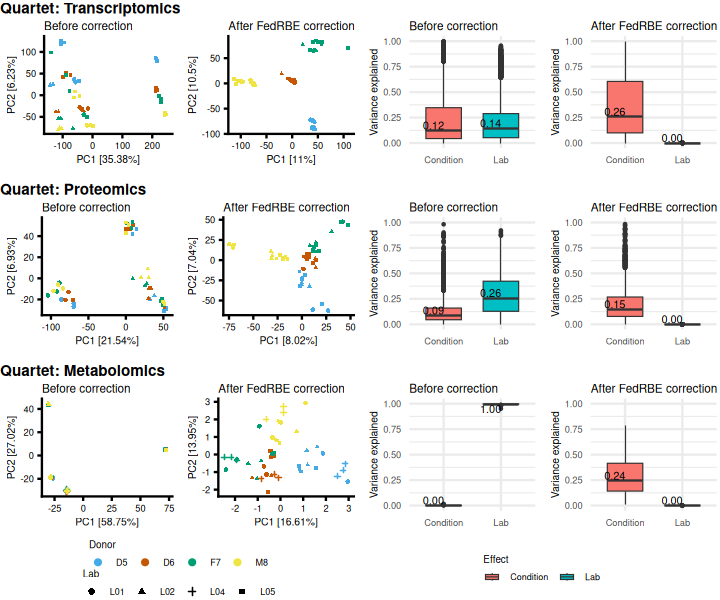

In [17]:
options(repr.plot.width = figure_width, repr.plot.height = figure_height)

if (figure_should_display_inline() && isTRUE(display_inline_preview)) {
  draw_modality_diagnostic_rows(quartet_modality_rows)
} else {
  message("Inline display skipped. Set display_inline_preview <- TRUE to render before saving.")
}

saved_path <- save_modality_diagnostic_rows(
  rows = quartet_modality_rows,
  output_path = output_path,
  width = figure_width,
  height = figure_height,
  dpi = figure_dpi
)

cat("Saved Quartet separated-modality diagnostics to", saved_path, "\n")

In [18]:
sessionInfo()

R version 4.5.2 (2025-10-31)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 24.04.4 LTS

Matrix products: default
BLAS/LAPACK: /home/yuliya-cosybio/miniforge3/envs/fedRBE/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Europe/Berlin
tzcode source: system (glibc)

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] viridis_0.6.5     viridisLite_0.4.3 ggsci_4.2.0       umap_0.2.10.0    
 [5] patchwork_1.3.2   gridExtra_2.3     lubridate_1.9.5   forcats_1.0.1    
 [9] stringr_1.6.0     dplyr_1.2.1       purrr_1.2.1     